In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tabulate
from IPython.display import Markdown
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import BaggingRegressor, RandomForestRegressor
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.inspection import permutation_importance
from sklearn.model_selection import TimeSeriesSplit, cross_val_score

In [2]:
ozone = pd.read_excel(r"C:\Users\darre\OneDrive\Documents\STATS 780\Assignment 2\Ozone.xlsx", sheet_name='Sheet1')
particulate = pd.read_excel(r"C:\Users\darre\OneDrive\Documents\STATS 780\Assignment 2\Particulate.xlsx", sheet_name='Sheet1')

In [3]:
# changing the second 2025-02-13 to 2025-02-14, assuming it is 
# a measurement error
# ozone and particulate are the original pollutant CSV's

for df in [ozone, particulate]:
    df["Date"] = pd.to_datetime(df["Date"])
    feb13 = (
        (df["Date"].dt.month == 2) &
        (df["Date"].dt.day == 13)
    )
    positions = np.flatnonzero(feb13.to_numpy())
    if len(positions) < 2:
        raise ValueError("Expected duplicate February 13 rows.")
    df.iloc[
        positions[1],
        df.columns.get_loc("Date")
    ] += pd.Timedelta(days=1)

In [4]:
#| output: false
# Transforming the original data for each pollutant
# then merging them
# ozone and particulate are the original CSV files

hour_columns = [f"H{i:02d}" for i in range(1, 25)]
def reshape_pollutant(df, name):
    df = df.melt(
        id_vars=["Station ID", "Pollutant", "Date"],
        value_vars=hour_columns,
        var_name="Hour",
        value_name=name
    )
    df["Date"] = (
        pd.to_datetime(df["Date"])
        + pd.to_timedelta(
            df["Hour"].str[1:].astype(int) - 1,
            unit="h"
        )
    )
    return (
        df[["Station ID", "Date", name]]
        .sort_values("Date")
        .reset_index(drop=True)
    )
ozone = reshape_pollutant(ozone, "ozone")
particulate = reshape_pollutant(particulate, "PM2.5")
merge = pd.merge(
    ozone,
    particulate,
    on=["Station ID", "Date"],
    how="inner"
)
merge

,Station ID,Date,ozone,PM2.5
0,29118,2025-01-01 00:00:00,19,7
1,29118,2025-01-01 01:00:00,23,2
2,29118,2025-01-01 02:00:00,23,1
3,29118,2025-01-01 03:00:00,23,1
4,29118,2025-01-01 04:00:00,24,0
...,...,...,...,...
8755,29118,2025-12-31 19:00:00,31,3
8756,29118,2025-12-31 20:00:00,34,2
8757,29118,2025-12-31 21:00:00,38,1
8758,29118,2025-12-31 22:00:00,35,1


In [5]:
#convert invalid values to NaNs so they don't become outliers
merge["ozone"] = merge["ozone"].replace([9999,-999,999], np.nan)
merge["PM2.5"] = merge["PM2.5"].replace([9999,-999,999], np.nan)

In [ ]:
# | label:
# | tbl-cap: Transformed data
Markdown(merge.head(5).to_markdown(index=False))

|   Station ID | Date                |   ozone |   PM2.5 |
|-------------:|:--------------------|--------:|--------:|
|        29118 | 2025-01-01 00:00:00 |      19 |       7 |
|        29118 | 2025-01-01 01:00:00 |      23 |       2 |
|        29118 | 2025-01-01 02:00:00 |      23 |       1 |
|        29118 | 2025-01-01 03:00:00 |      23 |       1 |
|        29118 | 2025-01-01 04:00:00 |      24 |       0 |

In [7]:
# Used linear interpolation to fill in missing values

merge["Date"] = pd.to_datetime(merge["Date"], errors="coerce")
merge = merge.sort_values(["Station ID", "Date"])

# Interpolate measurement columns, not the numeric station identifier.
value_cols = [
    col for col in merge.select_dtypes(include="number").columns
    if col != "Station ID"
]

# Interpolate using actual time intervals, independently for each station.
merge[value_cols] = (
    merge.set_index("Date")
    .groupby("Station ID")[value_cols]
    .transform(
        lambda values: values.interpolate(
            method="time",
            limit_area="inside",
        )
    )
    .to_numpy()
)

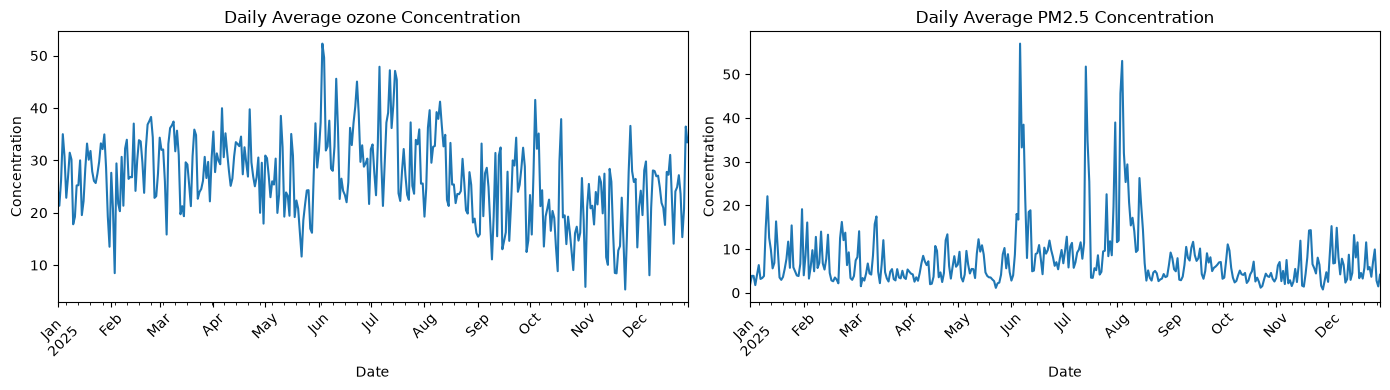

In [8]:
# Calculate and plot daily average concentrations
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

for i, pollutant in enumerate(["ozone", "PM2.5"]):

    daily = (
        merge.groupby(merge["Date"].dt.floor("D"))[pollutant]
        .mean()
    )

    daily.plot(
        ax=axes[i],
        title=f"Daily Average {pollutant} Concentration"
    )

    axes[i].set_xlabel("Date")
    axes[i].set_ylabel("Concentration")
    axes[i].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

In [9]:
# Calculating dominant frequency and dominant spectral power
# for ozone and PM2.5, adding them as features to merge
merge["Date"] = pd.to_datetime(merge["Date"])
merge = merge[["Date", "ozone", "PM2.5"]].sort_values("Date")

# Insert missing hourly timestamps so every window represents 24 hours.
intervals = merge["Date"].diff().dropna().dt.total_seconds()
merge = merge.set_index("Date")
hourly_index = pd.date_range(merge.index[0], merge.index[-1], freq="h")
merge = merge.reindex(hourly_index)
merge.index.name = "Date"
window_size = 24
frequencies = np.fft.rfftfreq(window_size, d=1)  # cycles per hour

# Each feature uses the 24 hours ending at that row.
for pollutant in ["ozone", "PM2.5"]:
    dominant_frequency = np.full(len(merge), np.nan)
    dominant_power = np.full(len(merge), np.nan)
    for end in range(window_size - 1, len(merge)):
        start = end - window_size + 1
        window = merge[pollutant].iloc[start:end + 1].to_numpy(dtype=float)

        # Leave features missing if this window has any missing observations.
        if not np.isfinite(window).all():
            continue
        window = window - window.mean()
        power = np.abs(np.fft.rfft(window)) ** 2

        # Ignore the zero-frequency component.
        positive_power = power[1:]
        if positive_power.max() == 0:
            continue
        dominant_idx = np.argmax(positive_power) + 1
        dominant_frequency[end] = frequencies[dominant_idx]
        dominant_power[end] = power[dominant_idx]
    merge[f"{pollutant}_fft_dominant_frequency"] = dominant_frequency
    merge[f"{pollutant}_fft_dominant_power"] = dominant_power

# Keep Date as a regular column in the resulting DataFrame.
merge = merge.reset_index()

In [10]:
# Check that timestamps are unique and exactly one hour apart.
dates = pd.to_datetime(merge["Date"], errors="raise")

# Build features on a copy to preserve the original data.
feature_data = merge.copy()
statistical_feature_cols = []
window_size = 24
for pollutant in ("ozone", "PM2.5"):

    # Latest concentration
    latest_col = f"{pollutant}_latest"
    feature_data[latest_col] = feature_data[pollutant]
    statistical_feature_cols.append(latest_col)

    # 24-hour rolling window
    rolling = feature_data[pollutant].rolling(
        window=window_size,
        min_periods=window_size
    )
    # Rolling mean and standard deviation
    mean_col = f"{pollutant}_mean_24h"
    std_col = f"{pollutant}_std_24h"
    feature_data[mean_col] = rolling.mean()
    feature_data[std_col] = rolling.std()
    statistical_feature_cols.extend([mean_col, std_col])

# Create next-hour prediction targets
target_cols = [
    "ozone_target_next_hour",
    "PM2.5_target_next_hour"
]
feature_data[target_cols[0]] = feature_data["ozone"].shift(-1)
feature_data[target_cols[1]] = feature_data["PM2.5"].shift(-1)

# Identify existing FFT features
fft_feature_cols = [
    col for col in merge.columns
    if col.endswith((
        "_fft_dominant_frequency",
        "_fft_dominant_power"
    ))
]
# Combine statistical and FFT predictors
predictor_cols = statistical_feature_cols + fft_feature_cols

# Prepare dataset for machine learning
model_data = feature_data[
    ["Date", *predictor_cols, *target_cols]
].dropna(subset=[*predictor_cols, *target_cols]).copy()
model_data.head()

,Date,ozone_latest,ozone_mean_24h,ozone_std_24h,PM2.5_latest,PM2.5_mean_24h,PM2.5_std_24h,ozone_fft_dominant_frequency,ozone_fft_dominant_power,PM2.5_fft_dominant_frequency,PM2.5_fft_dominant_power,ozone_target_next_hour,PM2.5_target_next_hour
23,2025-01-01 23:00:00,19.0,24.875000,3.745287,3.0,1.916667,1.411649,0.041667,1978.619355,0.125000,140.083261,21.0,3.0
24,2025-01-02 00:00:00,21.0,24.958333,3.629339,3.0,1.750000,0.944089,0.041667,1862.526975,0.083333,71.641016,25.0,2.0
25,2025-01-02 01:00:00,25.0,25.041667,3.605300,2.0,1.750000,0.944089,0.041667,1724.275013,0.083333,71.641016,24.0,1.0
26,2025-01-02 02:00:00,24.0,25.083333,3.586408,1.0,1.750000,0.944089,0.041667,1647.780062,0.083333,71.641016,23.0,1.0
27,2025-01-02 03:00:00,23.0,25.083333,3.586408,1.0,1.750000,0.944089,0.041667,1647.780062,0.083333,71.641016,18.0,1.0


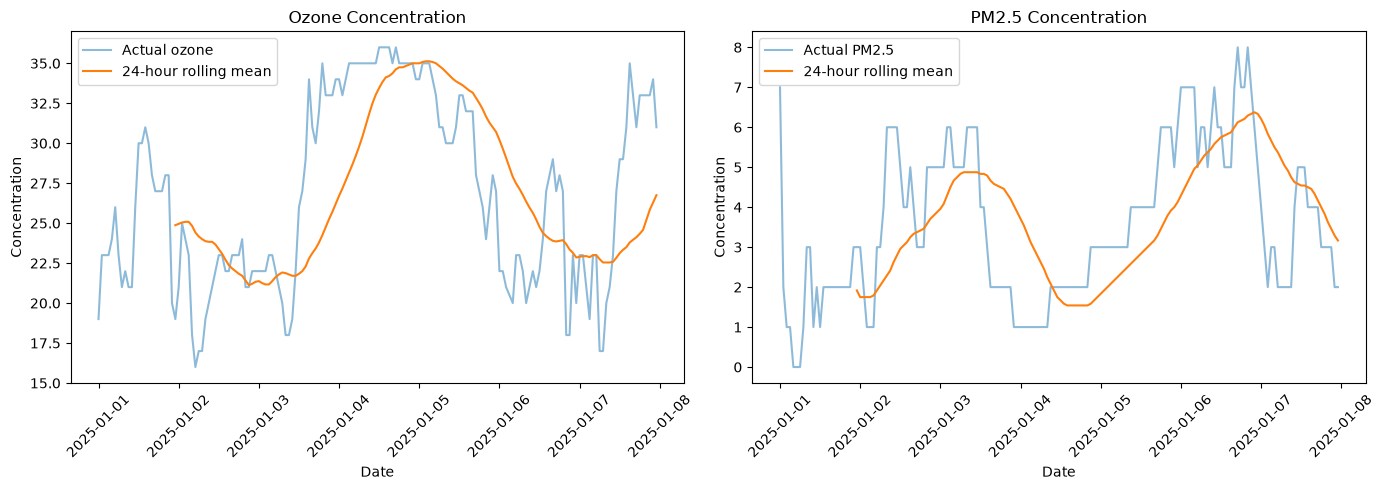

In [11]:
# Examine one week
plot_data = feature_data.loc[
    (feature_data["Date"] >= "2025-01-01") &
    (feature_data["Date"] < "2025-01-08")
]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot ozone
axes[0].plot(
    plot_data["Date"],
    plot_data["ozone"],
    label="Actual ozone",
    alpha=0.5
)

axes[0].plot(
    plot_data["Date"],
    plot_data["ozone_mean_24h"],
    label="24-hour rolling mean"
)

axes[0].set_title("Ozone Concentration")
axes[0].set_xlabel("Date")
axes[0].set_ylabel("Concentration")
axes[0].legend()
axes[0].tick_params(axis="x", rotation=45)

# Plot PM2.5
axes[1].plot(
    plot_data["Date"],
    plot_data["PM2.5"],
    label="Actual PM2.5",
    alpha=0.5
)

axes[1].plot(
    plot_data["Date"],
    plot_data["PM2.5_mean_24h"],
    label="24-hour rolling mean"
)

axes[1].set_title("PM2.5 Concentration")
axes[1].set_xlabel("Date")
axes[1].set_ylabel("Concentration")
axes[1].legend()
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

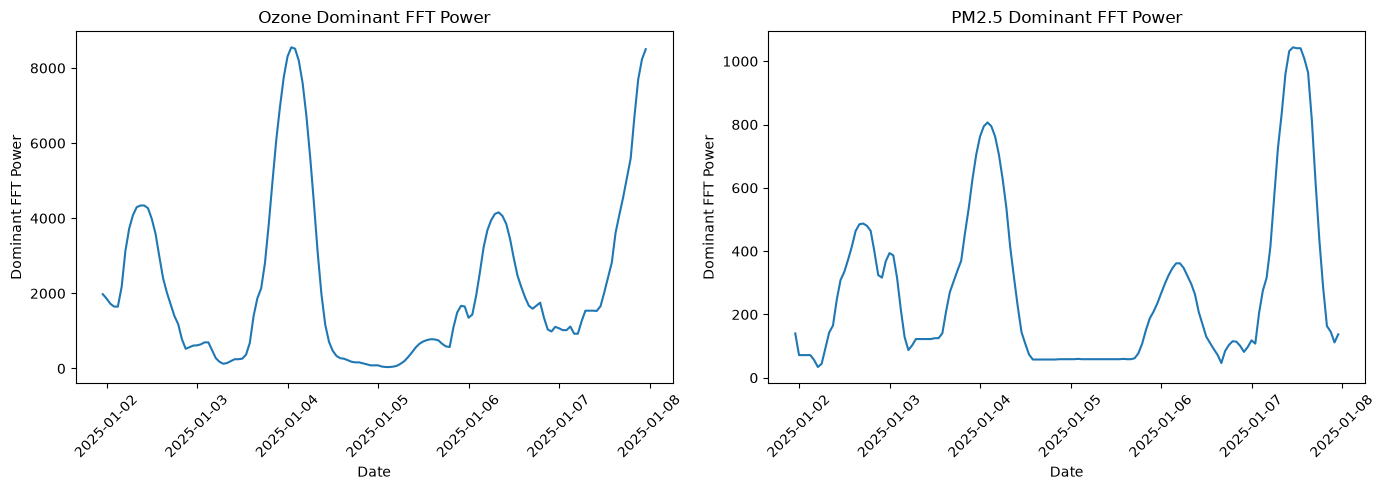

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Ozone FFT power
axes[0].plot(
    plot_data["Date"],
    plot_data["ozone_fft_dominant_power"]
)

axes[0].set_title("Ozone Dominant FFT Power")
axes[0].set_xlabel("Date")
axes[0].set_ylabel("Dominant FFT Power")
axes[0].tick_params(axis="x", rotation=45)

# PM2.5 FFT power
axes[1].plot(
    plot_data["Date"],
    plot_data["PM2.5_fft_dominant_power"]
)

axes[1].set_title("PM2.5 Dominant FFT Power")
axes[1].set_xlabel("Date")
axes[1].set_ylabel("Dominant FFT Power")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

In [13]:
# Training data: January–September
train = model_data.loc[
    model_data["Date"] < "2025-09-30 23:00"
].copy() # uses every on or before august 31 to train

# Testing data: October–December
test = model_data.loc[
    model_data["Date"] >= "2025-10-01"
].copy()

# Predictor and target matrices
X_train = train[predictor_cols]
X_test = test[predictor_cols]
targets = {
    "Ozone": "ozone_target_next_hour",
    "PM2.5": "PM2.5_target_next_hour"
}

In [14]:
# | label:
# | tbl-cap: RMSE per Tree Depth

# Finding optimal tree depth
depths = [1, 2, 3, 4, 5, 6, 7, 8]
depth_results = []

# 5-fold time-series cross-validation
tscv = TimeSeriesSplit(n_splits=5, gap=1)
for pollutant, target in targets.items():
    y_train = train[target]
    for depth in depths:
        tree = DecisionTreeRegressor(
            max_depth=depth,
            random_state=42
        )
        # Fit model on training data
        tree.fit(X_train, y_train)

        # Predictions on training data
        train_predictions = tree.predict(X_train)

        # Calculate training RMSE
        train_rmse = np.sqrt(
            mean_squared_error(y_train, train_predictions)
        )

        # Calculate cross-validation RMSE
        cv_scores = cross_val_score(
            tree,
            X_train,
            y_train,
            cv=tscv,
            scoring="neg_root_mean_squared_error"
        )
        cv_rmse = -cv_scores.mean()
        depth_results.append({
            "Pollutant": pollutant,
            "Max Depth": depth,
            "Training RMSE": train_rmse,
            "CV RMSE": cv_rmse
        })
depth_results_df = pd.DataFrame(depth_results)
Markdown(depth_results_df.to_markdown(index=False))

| Pollutant   |   Max Depth |   Training RMSE |   CV RMSE |
|:------------|------------:|----------------:|----------:|
| Ozone       |           1 |         8.86991 |   9.46728 |
| Ozone       |           2 |         6.21723 |   6.7879  |
| Ozone       |           3 |         4.99197 |   5.62005 |
| Ozone       |           4 |         4.61236 |   5.14348 |
| Ozone       |           5 |         4.49696 |   5.46991 |
| Ozone       |           6 |         4.33831 |   5.80685 |
| Ozone       |           7 |         4.17571 |   6.3423  |
| Ozone       |           8 |         3.9899  |   6.6827  |
| PM2.5       |           1 |         5.43232 |   5.84322 |
| PM2.5       |           2 |         3.32125 |   4.09163 |
| PM2.5       |           3 |         2.3771  |   3.14482 |
| PM2.5       |           4 |         2.04586 |   2.89956 |
| PM2.5       |           5 |         1.88178 |   2.98667 |
| PM2.5       |           6 |         1.73954 |   2.98975 |
| PM2.5       |           7 |         1.6099  |   3.15501 |
| PM2.5       |           8 |         1.49134 |   3.28176 |

In [15]:
# | label:
# | tbl-cap: RMSE's per Tree Number

# Tuning number of trees
n_trees = [10, 50, 100, 200, 500]
tree_results = []

# 5-fold time-series cross-validation
tscv = TimeSeriesSplit(n_splits=5, gap=1)
for pollutant, target in targets.items():
    y_train = train[target]
    for n in n_trees:
        models = {
            "Bagging": BaggingRegressor(
                estimator=DecisionTreeRegressor(),
                n_estimators=n,
                random_state=42,
                n_jobs=-1
            ),
            "Random Forest": RandomForestRegressor(
                n_estimators=n,
                max_features="sqrt",
                random_state=42,
                n_jobs=-1
            )
        }
        for name, model in models.items():

            # Fit model on training data
            model.fit(X_train, y_train)

            # Training predictions
            train_predictions = model.predict(X_train)

            # Calculate training RMSE
            train_rmse = np.sqrt(
                mean_squared_error(y_train, train_predictions)
            )
            # Calculate cross-validation RMSE
            cv_scores = cross_val_score(
                model,
                X_train,
                y_train,
                cv=tscv,
                scoring="neg_root_mean_squared_error"
            )
            cv_rmse = -cv_scores.mean()
            tree_results.append({
                "Pollutant": pollutant,
                "Model": name,
                "Number of Trees": n,
                "Training RMSE": train_rmse,
                "CV RMSE": cv_rmse
            })
tree_results_df = pd.DataFrame(tree_results)
Markdown(tree_results_df.to_markdown(index=False))

| Pollutant   | Model         |   Number of Trees |   Training RMSE |   CV RMSE |
|:------------|:--------------|------------------:|----------------:|----------:|
| Ozone       | Bagging       |                10 |        2.07544  |   5.60334 |
| Ozone       | Random Forest |                10 |        2.02684  |   6.53591 |
| Ozone       | Bagging       |                50 |        1.83465  |   5.44285 |
| Ozone       | Random Forest |                50 |        1.73943  |   6.42259 |
| Ozone       | Bagging       |               100 |        1.8016   |   5.40072 |
| Ozone       | Random Forest |               100 |        1.70243  |   6.33263 |
| Ozone       | Bagging       |               200 |        1.7828   |   5.4001  |
| Ozone       | Random Forest |               200 |        1.68335  |   6.38741 |
| Ozone       | Bagging       |               500 |        1.77593  |   5.40254 |
| Ozone       | Random Forest |               500 |        1.67174  |   6.33986 |
| PM2.5       | Bagging       |                10 |        0.88632  |   3.07872 |
| PM2.5       | Random Forest |                10 |        0.91577  |   3.79002 |
| PM2.5       | Bagging       |                50 |        0.800178 |   2.99967 |
| PM2.5       | Random Forest |                50 |        0.791971 |   3.79294 |
| PM2.5       | Bagging       |               100 |        0.775166 |   2.99102 |
| PM2.5       | Random Forest |               100 |        0.758972 |   3.75043 |
| PM2.5       | Bagging       |               200 |        0.770612 |   2.98277 |
| PM2.5       | Random Forest |               200 |        0.750266 |   3.75849 |
| PM2.5       | Bagging       |               500 |        0.768654 |   2.98218 |
| PM2.5       | Random Forest |               500 |        0.745995 |   3.74566 |

In [16]:
#| label:
#| tbl-cap: MAE and RMSE's per Tree-Based Method

# Implementing decision trees, bagging, random forests
models = {
    "Decision Tree": DecisionTreeRegressor(
        max_depth=4,
        random_state=42
    ),
    "Bagging": BaggingRegressor(
        estimator=DecisionTreeRegressor(),
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ),         
    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        max_features="sqrt",
        random_state=42,
        n_jobs=-1
    )
}
results = []
for pollutant, target in targets.items():
    y_train = train[target]
    y_test = test[target]
    for name, model in models.items():
        fitted_model = clone(model)
        fitted_model.fit(X_train, y_train)
        predictions = fitted_model.predict(X_test)
        mae = mean_absolute_error(y_test, predictions)
        rmse = mean_squared_error(
            y_test, predictions
        ) ** 0.5
        results.append({
            "Pollutant": pollutant,
            "Model": name,
            "MAE": mae,
            "RMSE": rmse
        })
results_df = pd.DataFrame(results)
Markdown(results_df.to_markdown(index=False))

| Pollutant   | Model         |      MAE |    RMSE |
|:------------|:--------------|---------:|--------:|
| Ozone       | Decision Tree | 2.66629  | 4.04062 |
| Ozone       | Bagging       | 2.85518  | 4.20191 |
| Ozone       | Random Forest | 3.14933  | 4.50693 |
| PM2.5       | Decision Tree | 0.951829 | 1.33372 |
| PM2.5       | Bagging       | 0.909369 | 1.38624 |
| PM2.5       | Random Forest | 0.989124 | 1.36047 |

In [17]:
# Multivariate random forest
target_cols = [
    "ozone_target_next_hour",
    "PM2.5_target_next_hour"
]
Y_train = train[target_cols]
Y_test = test[target_cols]
joint_rf = RandomForestRegressor(
    n_estimators=100,
    max_features="sqrt",
    random_state=42,
    n_jobs=-1
)
joint_rf.fit(X_train, Y_train)
joint_predictions = joint_rf.predict(X_test)
for i, pollutant in enumerate(["Ozone", "PM2.5"]):
    mae = mean_absolute_error(
        Y_test.iloc[:, i],
        joint_predictions[:, i]
    )
    rmse = mean_squared_error(
        Y_test.iloc[:, i],
        joint_predictions[:, i]
    ) ** 0.5
    print(f"{pollutant}: MAE = {mae:.3f}, RMSE = {rmse:.3f}")

Ozone: MAE = 3.130, RMSE = 4.466
PM2.5: MAE = 1.162, RMSE = 1.532


In [18]:
#| label:
#| tbl-cap: Predictor Importance

# Identifying predictor importance using permutation importance
importance_results = []
for pollutant, target in targets.items():
    # Train random forest
    rf = RandomForestRegressor(
        n_estimators=100,
        max_features="sqrt",
        random_state=42,
        n_jobs=-1
    )
    rf.fit(X_train, train[target])
    # Calculate permutation importance on testing data
    perm = permutation_importance(
        rf,
        X_test,
        test[target],
        scoring="neg_root_mean_squared_error",
        n_repeats=10,
        random_state=42,
        n_jobs=-1
    )
    for predictor, importance in zip(
        predictor_cols,
        perm.importances_mean
    ):
        importance_results.append({
            "Pollutant": pollutant,
            "Predictor": predictor,
            "Importance": importance
        })
importance_df = pd.DataFrame(importance_results)
Markdown(importance_df.sort_values(
        ["Pollutant", "Importance"],
        ascending=[True, False]).to_markdown(index=False))

| Pollutant   | Predictor                    |   Importance |
|:------------|:-----------------------------|-------------:|
| Ozone       | ozone_latest                 |   9.53598    |
| Ozone       | ozone_std_24h                |   0.152412   |
| Ozone       | PM2.5_mean_24h               |   0.0695955  |
| Ozone       | PM2.5_std_24h                |   0.0602815  |
| Ozone       | PM2.5_latest                 |   0.0528296  |
| Ozone       | ozone_mean_24h               |   0.0461345  |
| Ozone       | ozone_fft_dominant_power     |   0.0299937  |
| Ozone       | PM2.5_fft_dominant_power     |   0.0142412  |
| Ozone       | ozone_fft_dominant_frequency |   0.00309448 |
| Ozone       | PM2.5_fft_dominant_frequency |  -0.0201591  |
| PM2.5       | PM2.5_latest                 |   3.40507    |
| PM2.5       | PM2.5_mean_24h               |   0.335063   |
| PM2.5       | PM2.5_fft_dominant_power     |   0.10072    |
| PM2.5       | PM2.5_std_24h                |   0.0984258  |
| PM2.5       | ozone_latest                 |   0.0555562  |
| PM2.5       | ozone_fft_dominant_power     |   0.0396783  |
| PM2.5       | ozone_std_24h                |   0.0173808  |
| PM2.5       | ozone_mean_24h               |   0.00553657 |
| PM2.5       | PM2.5_fft_dominant_frequency |   0.0045893  |
| PM2.5       | ozone_fft_dominant_frequency |   0.00183209 |